# Policies and traffic lights: thresholds are policy, never regulation

**Question:** A p-value is a fact about the data and a light is a reading of it. On two samples whose truth we know, does the engine's default policy find the one that is wrong and leave the right one alone, and what happens to the colour when only the policy changes?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 02 of this topic (a first TestResult)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- read the engine's default `Policy` and say what each kind of threshold means;
- classify a p-value or a metric into a light with `Threshold.classify`, and draw the zones a threshold cuts out;
- show that a stricter and a more lenient policy leave the statistic and the p-value untouched and change only the colour;
- explain why Contraste words every light as a reading under a named policy, and where a regulation sets the zones itself.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Print the version of every package this notebook uses, to compare it with notebooks/requirements.txt
import csv
import importlib.metadata as md
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from riskvalidation.core.policy import Policy, Threshold, default_policy, policy_from_mapping
from riskvalidation.validation.calibration import pd_jeffreys
from riskvalidation.validation.market import basel_traffic_light

for name in ("riskvalidation", "numpy", "matplotlib", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2
pandas 3.0.6


## Data

Two scored samples with a **known truth**, committed in `data/examples/` as the examples of the bring-your-own-model guide (`docs/guides/02_validate-your-own-model.md`). Both are synthetic: the offline pipeline generates them from a seed (`data-pipeline/pipeline/io/examples.py`), so no third-party dataset and no dataset licence applies, and the repository's MIT licence covers them.

- `scored_sample_development.csv`: 2,000 obligors observed on 2024-12-31 whose PDs are calibrated by construction, because each default is a Bernoulli draw at its own PD.
- `scored_sample_current.csv`: 2,000 obligors observed on 2025-12-31 from a riskier population, whose defaults arrive at 1.5 times the PD. The ranking is intact and the level is under-estimated by a third.
- Columns: `id,observation_date,target,pd,segment`, where `target` is 1 for a default over the horizon.

Knowing the truth lets us ask a fair question of a policy: does it find the sample that is wrong and leave the right one alone? The next cell defines a small reader for the two files, with the standard library, and loads them.

In [2]:
# Read the two committed samples with the standard library: the outcome and the PD of every obligor
ROOT = Path("../../..").resolve()
EXAMPLES = ROOT / "data" / "examples"


def read_sample(name):
    with open(EXAMPLES / f"scored_sample_{name}.csv", newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    return np.array([int(r["target"]) for r in rows]), np.array([float(r["pd"]) for r in rows])


samples = {name: read_sample(name) for name in ("development", "current")}

## Method

A policy is the part of a validation that is a decision, and the engine keeps it apart from the tests on purpose. We first see what the truth is in the two samples, then open the policy, classify values by hand, run a test under three policies, write a policy as a file, and finish with the one family of tests whose zones a regulation itself defines.

### Step 1: what the truth is

The next cell counts, for each sample, the defaults it holds and the defaults its own PDs expect, and draws the two numbers side by side. A fair policy should object only where the two disagree.

development sample: obligors: 2000
    defaults: 100 | expected by the PDs: 111.2
current sample: obligors: 2000
    defaults: 207 | expected by the PDs: 138.1


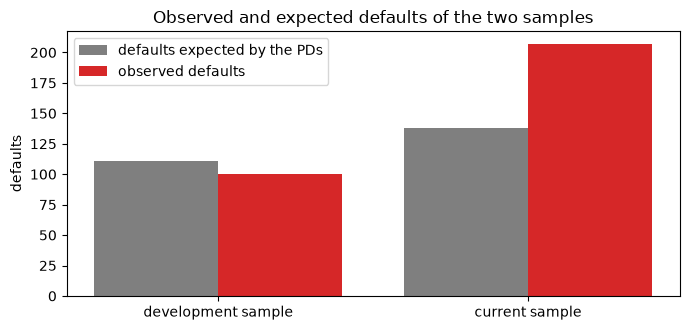

In [3]:
# Count the defaults each sample holds and the defaults its own PDs expect, and draw them side by side
NAMES = {"development": "development sample", "current": "current sample"}
observed = [int(y.sum()) for y, _ in samples.values()]
expected = [float(pd_hat.sum()) for _, pd_hat in samples.values()]
for name, (y, pd_hat) in samples.items():
    print(f"{NAMES[name]}: obligors: {len(y)}")
    print(f"    defaults: {int(y.sum())} | expected by the PDs: {pd_hat.sum():.1f}")

positions = np.arange(len(samples))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(positions - 0.2, expected, width=0.4, label="defaults expected by the PDs", color="tab:gray")
ax.bar(positions + 0.2, observed, width=0.4, label="observed defaults", color="tab:red")
ax.set_xticks(positions)
ax.set_xticklabels([NAMES[name] for name in samples])
ax.set_ylabel("defaults")
ax.set_title("Observed and expected defaults of the two samples")
ax.legend()
fig.tight_layout()
plt.show()

The development sample holds 100 defaults where its PDs expect 111.2, a little fewer than expected and well inside what chance gives. The current sample holds 207 where its PDs expect 138.1, half as many again, which is exactly the 1.5 factor of its construction. The figure shows the truth plainly, but a validator never has the truth; the validator has only the p-value of a test and a rule that turns it into a colour. That rule is the policy.

### Step 2: the packaged policy

A `Policy` is a named, versioned table of thresholds keyed by the identifier of a test. `default_policy()` loads the one the engine packages. There are three kinds of `Threshold`: `p_value` (red below `red`, amber below `amber`, green otherwise), `upper_bad` (larger is worse, like the PSI) and `lower_bad` (smaller is worse, like an AUC). The next cell prints the label, counts the thresholds by kind and reads the threshold of five tests that the topic uses.

In [4]:
# Open the packaged policy: its label, its thresholds by kind and the threshold of five tests
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
policy = default_policy()
print("policy:", policy.label)
print("thresholds by kind:", dict(Counter(t.kind for t in policy.thresholds.values())))
rows = []
for test_id in ("pd.jeffreys", "pd.binomial", "stability.psi", "disc.auc_vs_initial", "disc.auc"):
    cut = policy.threshold(test_id)
    rows.append({"test": test_id, "kind": "none" if cut is None else cut.kind,
                 "amber": None if cut is None else cut.amber, "red": None if cut is None else cut.red})
pd.DataFrame(rows)

policy: riskvalidation-default 2026.10.1
thresholds by kind: {'p_value': 25, 'upper_bad': 20, 'lower_bad': 3}


,test,kind,amber,red
0,pd.jeffreys,p_value,0.05,0.01
1,pd.binomial,p_value,0.05,0.01
2,stability.psi,p_value,0.05,0.01
3,disc.auc_vs_initial,p_value,0.05,0.01
4,disc.auc,none,NaN,NaN


The default policy, `riskvalidation-default 2026.10.1`, holds 48 thresholds: 25 of kind `p_value`, 20 of kind `upper_bad` and 3 of kind `lower_bad`. All four tests of the table that carry a threshold use the same pair of cut points, 0.05 for amber and 0.01 for red, which are the conventional 5 percent and 1 percent significance levels. `disc.auc` has no threshold at all, so a result for it can never be coloured; as notebook 02 showed, it comes back `not evaluated`. The ECB (2019) instructions that define these tests set no pass or fail threshold, and the source note of each threshold in the engine says so.

### Step 3: classify by hand

`Threshold.classify` is the whole rule: a threshold is built from a kind and two cut points, and it maps a value to a light. The next cell builds one threshold of each kind, with cut points made up for the illustration, and classifies six values, the last of them a missing one.

In [5]:
# Build one threshold of each kind and classify a few values: the whole rule is Threshold.classify
cuts = {
    "p_value": Threshold(kind="p_value", amber=0.05, red=0.01),
    "upper_bad": Threshold(kind="upper_bad", amber=0.10, red=0.25),
    "lower_bad": Threshold(kind="lower_bad", amber=0.60, red=0.50),
}
tried = [("p_value", 0.20), ("p_value", 0.03), ("p_value", 0.004)]
tried += [("upper_bad", 0.12), ("lower_bad", 0.55), ("lower_bad", None)]
lights = [LIGHT[cuts[kind].classify(value).value] for kind, value in tried]
table = pd.DataFrame(tried, columns=["kind", "value"])
table["light"] = lights
table

,kind,value,light
0,p_value,0.200,green
1,p_value,0.030,amber
2,p_value,0.004,red
3,upper_bad,0.120,amber
4,lower_bad,0.550,amber
5,lower_bad,NaN,not evaluated


The three rows of the first kind show the rule: a p-value of 0.20 is green, 0.03 is amber and 0.004 is red. The `upper_bad` value 0.12 is amber because it is at or above 0.10 and below 0.25, and the `lower_bad` value 0.55 is amber because it is at or below 0.60 and above 0.50. A missing value is `not evaluated`, never silently green. The two thresholds of the second and third kinds are illustrations, not recommendations.

### Step 4: the zones, drawn

The same rule over a whole range of values is easier to see. The next cell asks each threshold for the light of 300 values and draws the answer as a colour strip.

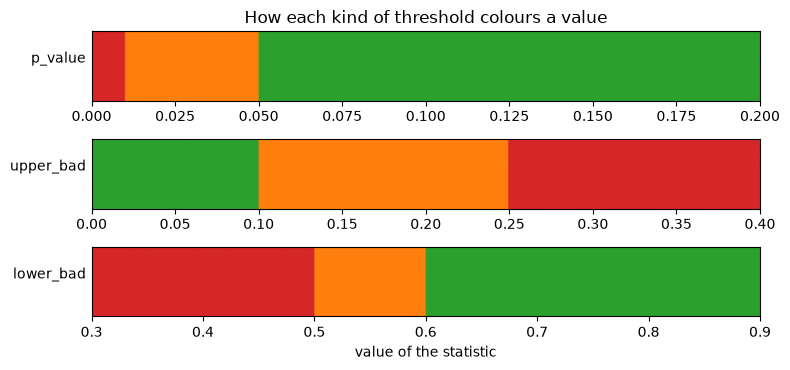

In [6]:
# Colour a grid of values with each threshold, to see the zones the rule cuts out
codes = {"green": 0, "amber": 1, "red": 2}
colours = ListedColormap(["tab:green", "tab:orange", "tab:red"])
ranges = {"p_value": (0, 0.2), "upper_bad": (0, 0.4), "lower_bad": (0.3, 0.9)}
fig, axes = plt.subplots(3, 1, figsize=(8, 3.8))
for ax, (kind, cut) in zip(axes, cuts.items()):
    low, high = ranges[kind]
    grid = np.linspace(low, high, 300)
    strip = [[codes[cut.classify(value).value] for value in grid]]
    ax.imshow(strip, aspect="auto", extent=(low, high, 0, 1), cmap=colours, vmin=0, vmax=2)
    ax.set_yticks([])
    ax.set_ylabel(kind, rotation=0, ha="right")
axes[0].set_title("How each kind of threshold colours a value")
axes[-1].set_xlabel("value of the statistic")
fig.tight_layout()
plt.show()

Each strip is one threshold. In the `p_value` strip red occupies the narrow band below 0.01 and amber the band up to 0.05, and everything above is green: a small p-value is the bad direction. The `upper_bad` strip is green at the left and turns amber at 0.10 and red at 0.25: a large value is the bad direction. The `lower_bad` strip is the mirror image. The figure shows that the three kinds are one idea with the bad direction changed; it does not say where the cut points should be, which no figure can.

### Step 5: one test, two samples, the default policy

Now the engine. `pd_jeffreys` takes the number of obligors, the number of defaults and the applied PD, here the sample's mean PD, and applies the policy it is given. The next cell runs it on both samples under the default policy, as notebook 02 did on 50 cards.

In [7]:
# Run the Jeffreys test on both samples under the default policy
jeffreys = {}
for name, (y, pd_hat) in samples.items():
    args = dict(n=len(y), d=int(y.sum()), pd=float(pd_hat.mean()))
    jeffreys[name] = pd_jeffreys(**args, policy=policy, model_id=name, segment="portfolio")
table = pd.DataFrame(
    {
        "sample": [NAMES[name] for name in samples],
        "defaults": observed,
        "expected": [round(e, 1) for e in expected],
        "p-value": [f"{result.p_value:.3e}" for result in jeffreys.values()],
        "light": [LIGHT[result.light.value] for result in jeffreys.values()],
    }
)
table

,sample,defaults,expected,p-value,light
0,development sample,100,111.2,8.629e-01,green
1,current sample,207,138.1,6.047e-09,red


The default policy finds the truth. The development sample, calibrated by construction, has a p-value of 8.629e-01 and is green, so the test sees no sign that its PDs are too low. The current sample, with 207 defaults against 138.1 expected, has a p-value of 6.047e-09 and is red. With 2,000 obligors per sample the test has the power to see a one-third shortfall in the level and the sample that is right is left alone, which is what we asked of it. This result depends on the policy: the next step changes the policy and keeps everything else.

### Step 6: the same p-value, another policy

A policy is data, so an institution can hold a stricter one or a more lenient one. The next cell builds two policies for this one test, as `Policy` objects of one `Threshold` each: `strict-demo` turns amber below 0.90 and red below 0.50, and `lenient-demo` turns amber below 1e-6 and red below 1e-9. Both are illustrations. The test then runs on the same arrays under all three policies.

In [8]:
# Build a stricter and a more lenient policy for the same test and read both samples under the three policies
strict = Policy(
    policy_id="strict-demo",
    version="1",
    description="illustration: a stricter reading of one test",
    thresholds={"pd.jeffreys": Threshold(kind="p_value", amber=0.90, red=0.50)},
)
lenient = Policy(
    policy_id="lenient-demo",
    version="1",
    description="illustration: a more lenient reading of one test",
    thresholds={"pd.jeffreys": Threshold(kind="p_value", amber=1e-6, red=1e-9)},
)
policies = {"default policy": policy, "strict-demo": strict, "lenient-demo": lenient}
rows = []
for name, (y, pd_hat) in samples.items():
    args = dict(n=len(y), d=int(y.sum()), pd=float(pd_hat.mean()))
    for label, in_use in policies.items():
        result = pd_jeffreys(**args, policy=in_use, model_id=name, segment="portfolio")
        rows.append({"sample": NAMES[name], "policy": label, "p-value": f"{result.p_value:.3e}",
                     "light": LIGHT[result.light.value]})
pd.DataFrame(rows)

,sample,policy,p-value,light
0,development sample,default policy,8.629e-01,green
1,development sample,strict-demo,8.629e-01,amber
2,development sample,lenient-demo,8.629e-01,green
3,current sample,default policy,6.047e-09,red
4,current sample,strict-demo,6.047e-09,red
5,current sample,lenient-demo,6.047e-09,amber


The p-value column does not change from one policy to the next; only the light does. Under `strict-demo` the calibrated development sample turns amber without any change in the data, and under `lenient-demo` the current sample, which is red under the default policy, turns amber because its p-value is below 1e-6 but not below 1e-9. The statistic did not move, the sample did not move and the colour moved twice. This is the reason a `TestResult` records the label of the policy that coloured it and the two cut points: the light can always be read again under another policy without running the test.

### Step 7: the lights, drawn

The next cell puts the two p-values on a logarithmic axis and draws the cut points of the three policies as vertical lines: a point to the left of a line is below that threshold.

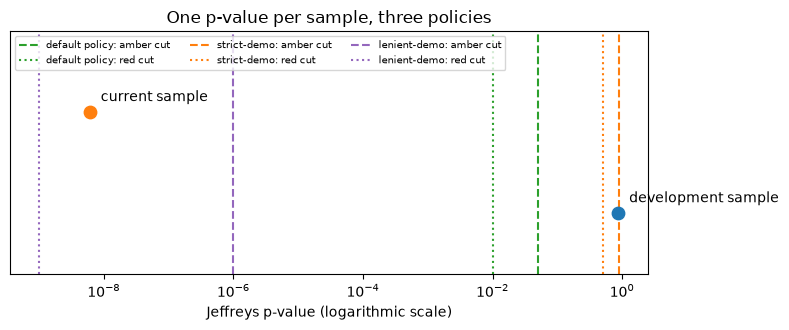

In [9]:
# Draw the two p-values against the cut points of the three policies
fig, ax = plt.subplots(figsize=(8, 3.4))
for row, name in enumerate(samples):
    p_value = jeffreys[name].p_value
    ax.scatter([p_value], [row], s=80, zorder=3)
    ax.annotate(NAMES[name], (p_value, row), textcoords="offset points", xytext=(8, 8))
styles = (
    ("default policy", policy, "tab:green"),
    ("strict-demo", strict, "tab:orange"),
    ("lenient-demo", lenient, "tab:purple"),
)
for label, in_use, colour in styles:
    cut = in_use.threshold("pd.jeffreys")
    ax.axvline(cut.amber, color=colour, linestyle="--", label=f"{label}: amber cut")
    ax.axvline(cut.red, color=colour, linestyle=":", label=f"{label}: red cut")
ax.set_xscale("log")
ax.set_yticks([])
ax.set_ylim(-0.6, 1.8)
ax.set_xlabel("Jeffreys p-value (logarithmic scale)")
ax.set_title("One p-value per sample, three policies")
ax.legend(fontsize=7, ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

The development sample sits at the right, at 0.863, just below the strict policy's amber cut of 0.90 and above its red cut of 0.50, so only the strict policy sees it amber; it lies to the right of every cut point of the other two policies, so it is green there. The current sample sits at the left, near 6e-9: it is left of the default cut of 0.01 and of the strict one, so it is red there, left of the lenient amber cut at 1e-6 but right of its red cut at 1e-9, so it is amber there. The log axis spans nine orders of magnitude; on a linear axis the cut points of the default policy would be indistinguishable from zero. The figure shows where a policy draws its lines relative to the data, and it does not tell you which lines are right.

### Step 8: a policy is a versioned file

The engine ships its default policy as a JSON file, and `policy_from_mapping` builds a policy from a mapping of that shape (`load_policy` reads the file and calls it). The next cell writes the shape of the strict policy as text, reads it back with the engine and checks two things about the copy. No file is written.

In [10]:
# Write the shape of a policy file as text, read it back with the engine and check it behaves like the original
text = json.dumps(
    {
        "policy_id": "strict-demo",
        "version": "1",
        "description": "illustration: a stricter reading of one test",
        "thresholds": {"pd.jeffreys": {"kind": "p_value", "amber": 0.90, "red": 0.50, "source": "illustration"}},
    },
    indent=2,
    ensure_ascii=False,
)
print(text)
reloaded = policy_from_mapping(json.loads(text))
print("same label:", reloaded.label == strict.label)
print("same amber cut:", reloaded.threshold("pd.jeffreys").amber == strict.threshold("pd.jeffreys").amber)

{
  "policy_id": "strict-demo",
  "version": "1",
  "description": "illustration: a stricter reading of one test",
  "thresholds": {
    "pd.jeffreys": {
      "kind": "p_value",
      "amber": 0.9,
      "red": 0.5,
      "source": "illustration"
    }
  }
}
same label: True
same amber cut: True


The text is the whole policy: an identifier, a version, a description and one threshold with its source. The engine rebuilds it with the same label and the same amber cut, so a policy can be reviewed, versioned and signed off as a file, and a result can name it by label. That is how an institution holds its own policy: as a document under change control, and not as a number buried in code.

### Step 9: where a regulation sets the zones

For the credit tests of this topic, no supervisory text sets thresholds. A few tests of other topics are the exception, because the regulation they implement defines its own zones. `basel_traffic_light` assigns the zone of the Basel backtesting traffic light (MAR32.9, Table 1) from the number of exceptions of a 99 percent value-at-risk model over 250 days, and the zone comes from the cumulative binomial probability of that count under the model's own coverage, $P(X \le k)$ with $X \sim \mathrm{Bin}(250, 0.01)$: amber where it first reaches 95 percent, red at 99.99 percent. The next cell runs the test for 0 to 12 exceptions and draws the cumulative probability coloured by zone.

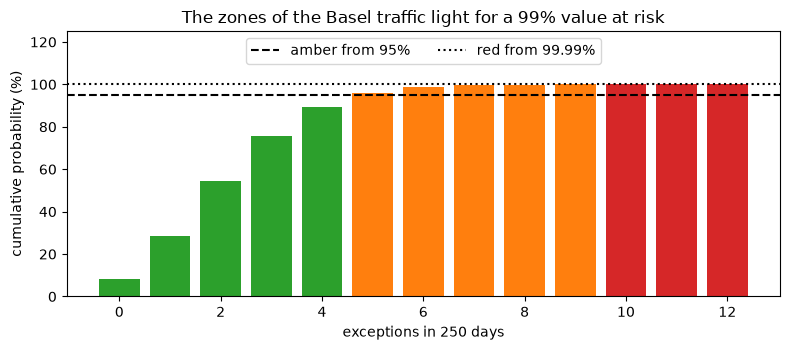

,exceptions,cumulative probability (%),zone,multiplier
4,4,89.2188,green,1.50
5,5,95.8817,amber,1.70
9,9,99.9750,amber,1.92
10,10,99.9946,red,2.00


In [11]:
# The Basel traffic light for a 99% value at risk over 250 days: the zone of the regulation, from 0 to 12 exceptions
rows = []
for k in range(13):
    days = np.zeros(250)
    days[:k] = 1
    result = basel_traffic_light(days)
    rows.append({"exceptions": k, "cumulative probability (%)": round(result.metric, 4), "zone": result.light.value,
                 "multiplier": result.extras["mar32_multiplier"]})
zones = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
colours = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
ax.bar(zones["exceptions"], zones["cumulative probability (%)"], color=[colours[z] for z in zones["zone"]])
ax.axhline(95, color="black", linestyle="--", label="amber from 95%")
ax.axhline(99.99, color="black", linestyle=":", label="red from 99.99%")
ax.set_ylim(0, 125)
ax.set_xlabel("exceptions in 250 days")
ax.set_ylabel("cumulative probability (%)")
ax.set_title("The zones of the Basel traffic light for a 99% value at risk")
ax.legend(loc="upper center", ncol=2)
fig.tight_layout()
plt.show()
zones["zone"] = zones["zone"].map(LIGHT)
zones.iloc[[4, 5, 9, 10]]

Up to 4 exceptions the cumulative probability is below 95 percent (89.2188 at 4) and the zone is green with a multiplier of 1.50; at 5 it reaches 95.8817 and the zone turns amber with a multiplier of 1.70, and it stays amber through 9 (99.9750, multiplier 1.92); at 10 it reaches 99.9946 and the zone is red with a multiplier of 2.00. Here the colour is not a policy choice: it is the zone the text defines for the count, and the result names its source. The bars for 0 to 3 exceptions are green and below the lines. The figure shows a case where the thresholds are regulation, and even there the light is the zone of the text for the number computed, never a verdict that an institution complies.

## Results

**Answer:** Under the default policy the engine finds the truth: the calibrated development sample (100 defaults, 111.2 expected) is green with a p-value of 0.863, and the current sample (207 defaults, 138.1 expected) is red with a p-value of 6.047e-09. Change only the policy and the colour changes while the p-value does not: the strict policy turns the right sample amber and the lenient one turns the wrong sample amber.

- **The colour is a reading, not a property.** A light means something only together with the policy that produced it, and the `TestResult` carries that label for this reason.
- **Missing thresholds are visible.** A test with no threshold in the policy, like the AUC, returns `not evaluated`; it is never silently green.
- **The wording rule of the product.** A Contraste light says "under policy `riskvalidation-default 2026.10.1`, the p-value is below 0.01"; it never says that a model is compliant or non-compliant. For the credit tests the supervisory sources the engine cites (ECB 2019; BCBS Working Paper 14, 2005) set no thresholds, and the source notes of the thresholds say so.
- **The exception.** Where the regulatory text sets the zones, as for the Basel backtesting traffic light (5 exceptions are amber and 10 are red), the engine computes the zone of that text and names its source. Topics 07 and 09 of this notebook set show the market-risk and the interest-rate-risk tests.

What this notebook does not do is choose a policy for you: that is the job of the institution's model risk function.

## Summary

- A `Policy` is versioned data that maps a test identifier to a `Threshold` of kind `p_value`, `upper_bad` or `lower_bad`; the default policy holds 48 of them and the credit tests are coloured with 0.05 and 0.01.
- The same statistic and p-value give different lights under different policies, and the result records the policy label and cut points.
- A test with no threshold is `not evaluated`, never green.
- For the credit tests, no supervisory source sets thresholds, so they are an institution's policy. Where a regulation defines zones (MAR32.9, SRP31), the engine computes the zone of the text and names its source.

**What to try next.** Add a threshold for `disc.auc` to a policy of your own (kind `lower_bad`) and rerun the AUC of notebook 02 under it. Then continue with notebook 04, which runs a whole battery under one policy.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: they define the tests and set no pass or fail thresholds. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), the Jeffreys interval behind the test. https://doi.org/10.1214/ss/1009213286
- This repository: `docs/design/SDD.md` (non-goal 1: no light is a compliance verdict) and `docs/guides/02_validate-your-own-model.md`.
- BCBS, Basel Framework, MAR32 (internal models approach: backtesting and the traffic light, MAR32.9). https://www.bis.org/basel_framework/chapter/MAR/32.htm
- BCBS, Basel Framework, SRP31 (interest rate risk in the banking book, outlier test, SRP31.82 to SRP31.83). https://www.bis.org/basel_framework/chapter/SRP/31.htm